# COMP8410 Advanced Topic in Artificial Intelligence

# Notebook 3 - Global Pricing (Which price tier fits each new K-pop merchandise item?)

> this will help to check if price can match which market price and not over price.

### Introduction

When a K-pop merchandise launches new comeback merchandise with Artist' single in Korean and US online stores, it must decide which **price tier**  fits each item, and spot listings that look overpriced compared with similar products.



This notebook compares two graph neural networks (GNNs) that predict the price tier of each product from its features **and** from the products it is linked to.

| | System A - Standard System Overview | System B - Global System Overview | Baseline |
|---|---|---|---|
| Model | **GAT** | **FAGCN**  | **MLP** with no graph |
| Idea | attention over neighbours; weights are always positive, so it acts as a **low-pass filter** (neighbours are assumed similar) | self-gating mixes **low- and high-frequency** signals with signed weights, so it can also learn from neighbours that are different | uses only the item's own features |

### Linked with COMP8410 Knowledge
* Week 11 - GNNs under homophily and heterophily
Furthermore, this experiment will test and check through
  * **Same-artist edges:** a sticker and a lightstick of one group usually sit in different price tiers.
  * **Same-category edges:** products of the same type usually cost about the same 

### Dataset
**KPop Online Merchandise Prices** (Wan, 2022), a public Kaggle dataset and No token is needed - https://www.kaggle.com/datasets/ericwan1/kpop-merchandise-prices
> This dataset will help to compare a price in the actual market from past.

**References**
- Bo, D., Wang, X., Shi, C., & Shen, H. (2021). Beyond low-frequency information in graph convolutional networks. *Proceedings of the AAAI Conference on Artificial Intelligence, 35*(5), 3950–3957. https://multisearch.mq.edu.au/permalink/61MACQUARIE_INST/1gnm2jp/cdi_crossref_citationtrail_10_1609_aaai_v35i5_16514
- Zhu, J., Yan, Y., Zhao, L., Heimann, M., Akoglu, L., & Koutra, D. (2020). Beyond homophily in graph neural networks: Current limitations and effective designs. *Advances in Neural Information Processing Systems (NeurIPS), 33*, 7793–7804. https://multisearch.mq.edu.au/permalink/61MACQUARIE_INST/1gnm2jp/cdi_arxiv_primary_2006_11468

# 1. Import Libraries and Set-up

In [66]:
# Shared settings: identical in every notebook (if you change one, change all) 
from pathlib import Path
import os, sys, json, time, random, platform, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# Experiment Settings for seed
SEED = 42


SYSTEMS = {"A": "Standard System Overview", "B": "Global System Overview"}

**GPU Checking**
* Cost estimation for computing unit and GPU type
* All of the price references and Google Colab Information in **ENV_SETUP.ipynb**

In [67]:
COLAB_PRICE_PER_UNIT_USD = 9.99 / 100

COLAB_UNITS_PER_HOUR_BY_GPU = {"T4": 1.19, "L4": 1.71, "A100": 5.40}


# GPU Detection
try:

    import torch

    _gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

except ImportError:

    _gpu = "CPU"


# Compute the approximate GPU cost per hour in USD
GPU_HOURLY_USD = next(
    (u for k, u in COLAB_UNITS_PER_HOUR_BY_GPU.items() if k in _gpu), 0.0 ) * COLAB_PRICE_PER_UNIT_USD

In [68]:
#  Random Seed Function 
def set_seed(seed: int = SEED) -> None:

    
    random.seed(seed)

    np.random.seed(seed)

    try:
        import torch

        torch.manual_seed(seed)

        torch.cuda.manual_seed_all(seed)

    except ImportError:
        
        pass

In [69]:
#  Device Detection Function 


def get_device() -> str:

    try:
        import torch

        if torch.cuda.is_available():

            return "cuda"

    except ImportError:
        pass

    return "cpu"



set_seed()


print(
    f"device: {get_device()} | "
    f"GPU: {_gpu} ≈ US${GPU_HOURLY_USD:.3f}/hour"
)

device: cuda | GPU: NVIDIA L4 ≈ US$0.171/hour


**Helper Function**

This will help me to check about run metadata (Dataset), timing, outcomes, which will use in all pairs model

So there is mainly feature:
* Check GPU 
* Model management
* Saved program environment
* GPU memory setuo
* Timimg measure
* Save final experiment result

In [70]:
# GPU Type and Capability
def gpu_dtype():

    import torch

    if torch.cuda.is_available():

        if torch.cuda.get_device_capability()[0] >= 8:
            return torch.bfloat16
        else:
            return torch.float16

    return torch.float32

In [71]:
# Transformers Output from AI model to Tensor Function - Model Management
def as_tensor(out):

    """get_*_features returns a tensor in transformers 4.x; newer versions may wrap it in an output object."""

    if hasattr(out, "pooler_output") and out.pooler_output is not None:

        return out.pooler_output

    if hasattr(out, "image_embeds"):
        
        return out.image_embeds

    if hasattr(out, "text_embeds"):

        return out.text_embeds

    return out if hasattr(out, "shape") else out[0]

In [72]:
# Store Environment Information Function 

def env_info():

    """Saved inside every result file as evidence of when and where it was produced."""


    info = {

        "timestamp_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),

        "python": platform.python_version(),

        "os": platform.platform()

    }

    for pkg in ("torch", "transformers", "diffusers", "torch_geometric"):

        try:

            info[pkg] = __import__(pkg).__version__

        except Exception:

            info[pkg] = None

    try:

        import torch

        info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None


    except Exception:

        info["gpu"] = None

    return info

In [73]:
# Logging Function for GPU Synchronization for Accurate Timing and Checking GPU working

def sync_gpu():

    try:

        import torch

        if torch.cuda.is_available():

            torch.cuda.synchronize()

    except ImportError:

        pass

In [74]:
# Free GPU Memory Function to Avoid Out of Memory Errors

def free_gpu():

    import gc

    gc.collect()

    try:

        import torch

        torch.cuda.empty_cache()

    except ImportError:

        pass

In [75]:

# Timer -> for measuring latency and peak GPU memory usage, leading to performance evaluation and cost analysis of AI models

class Timer:
    #  check model performance from Latency and Peak VRAM


    def __init__(self):
        # Constructor will initialize the Timer object and set default values for latencies and peak VRAM usage.

        self.latencies, self.peak_vram_gb = [], None

        try:
           # start checking GPU
            import torch

            if torch.cuda.is_available():
    
                torch.cuda.reset_peak_memory_stats()

        except ImportError:

            pass




    def add(self, seconds, n_items=1):
        # this will calculate the average time per item and store it in the latencies list for further analysis.

        self.latencies.extend([seconds / n_items] * n_items)


    def finish(self):
        # this function is called after all processing is done to finalize the timing and memory usage data.
        try:

         # check GPU again
            import torch

            if torch.cuda.is_available():

                torch.cuda.synchronize()


                self.peak_vram_gb = torch.cuda.max_memory_allocated() / 1024**3
               # check GPU Memory usage and convert to GB

        except ImportError:

            pass

        return self



    def business(self):

        # this function summarizes the business performance metrics of the AI model to provide insights for business decision-making and cost analysis.

        mean = float(np.mean(self.latencies)) if self.latencies else float("nan")
        # Compute the average latency in seconds for processing each item, and handle cases where there are no latencies recorded by returning NaN.

        return {

            "mean_latency_s": round(mean, 4),


            "p95_latency_s": round(float(np.percentile(self.latencies, 95)), 4) if self.latencies else None,
             # 95th percentile latency, indicating that 95% of the items were processed in this time or less. If there are no latencies recorded, it returns None.

            "gpu_hourly_usd": round(GPU_HOURLY_USD, 4),

            "cost_per_1000_usd": round(mean * 1000 / 3600 * GPU_HOURLY_USD, 4),

            "peak_vram_gb": None if self.peak_vram_gb is None else round(self.peak_vram_gb, 2),
          
        }

In [76]:
# JSON file handling function to manage data that cannot be directly converted to JSON, such as NumPy Scalars or special object types.
def _json_default(o):
    

    return o.item() if hasattr(o, "item") else str(o)

In [77]:
# Save Result Function

# Project folders: relative paths work on both Colab and Windows
ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW = ROOT / "Datasets"
PROCESSED = RAW / "processed"
AMAZON_DIR = RAW / "Amazon2023_Merchandise_Data"
RESULTS = ROOT / "Results"
FIGURES, TABLES, METRICS = RESULTS / "figures", RESULTS / "tables", RESULTS / "metrics"
for _d in (PROCESSED, AMAZON_DIR, FIGURES, TABLES, METRICS):
    _d.mkdir(parents=True, exist_ok=True)


def save_result(task, system, model_id, technical, business,
                governance, notes="", items=None, extra=None):

    records = {

        "task": task,

        "system": system,

        "model_id": model_id,

        "technical": technical,

        "business": business,

        "governance": governance,

        "notes": notes,

        "env": env_info(),

        "extra": extra or {}

    }

    path = METRICS / f"{task}__{system}.json"

    path.write_text(
        json.dumps(
            records,
            indent=2,
            ensure_ascii=False,
            default=_json_default
        ),
        encoding="utf-8"
    )

    if items is not None:

        items.to_csv(
            TABLES / f"{task}__{system}_items.csv",
            index=False
        )

    print("saved", path)

    return records

## 3. Task Settings

For this task, I compares three models to see how well they can predict K-pop merchandise price categories. System A uses GAT, System B uses FAGCN, and the baseline is a simple MLP that does not use graph connections. All three models predict whether a product belongs to the **budget, mid, or premium** price category.

### Data
- I only use `all_shops.csv` from the KPop Online Merchandise Prices dataset because it already includes data from all six shops. Using the other six files as well would duplicate the products. this is form my survey
- I divide the products into three roughly equal-sized price groups: **budget, mid, and premium**. These are the categories the models try to predict.
- I do not include the actual price as an input because that would give the models the answer. Instead, they use other product information, such as the product name, store, region, whether the item is sold out, and whether it is autographed.

In [78]:
TASK = "3_Global_Pricing"
DATA_DIR = RAW / "KPop Online Merchandise Prices"  
DATA_FILE = "all_shops.csv"           # combines the other 6 shop files -> read only this one to avoid duplicates # combines the other 6 shop files -> read only this one to avoid duplicates
COLUMN_MAP = {}                       # override auto-detection,
CURRENCY_TO_USD = {"USD": 1.0, "KRW": 0.00073, "JPY": 0.0067}   # come with cite and source date
N_TIERS = 3                           # price ranking
MAX_NEIGHBOURS = 10                   
EDGE_TYPES = ["artist", "category"]   
PRIMARY_GRAPH = "artist"              # the graph used for the A vs B decision -> real bu growth
MODELS = {
    "A": {"kind": "gat", "hidden": 64, "heads": 4, "dropout": 0.5},
    "B": {"kind": "fagcn", "hidden": 64, "layers": 2, "eps": 0.3, "dropout": 0.5},
    "baseline_mlp": {"kind": "mlp", "hidden": 64, "dropout": 0.5},
}
TRAIN = {"epochs": 300, "lr": 0.005, "weight_decay": 5e-4, "patience": 50}
SPLIT = {"train": 0.6, "val": 0.2, "test": 0.2}
N_SEEDS = 5                           # repeat every model on 5 random splits -> mean and std

# 4. Load data and Clean it

Column names are detected automatically (name, price, artist, store, category). 

> If you use your local GPU, you can change dataset to be file path from notebook directly
> But if you use google colab extenntion , you must upload all content file of data in to colab content first

In my case, I do upload it to google colab content direecly which right click on local file and upload to colab

In [79]:
from google.colab import files
from pathlib import Path
import shutil

# Upload the local dataset to Colab, then move it into DATA_DIR where load_prices() reads it
target = DATA_DIR / DATA_FILE
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not target.exists():
    uploaded = Path("/content") / DATA_FILE
    if not uploaded.exists():
        files.upload()                                   # choose all_shops.csv from my laptop
    if not uploaded.exists():
        raise FileNotFoundError("Please upload all_shops.csv")
    shutil.copy2(uploaded, target)

print("Dataset ready:", target)

Dataset ready: /content/Datasets/KPop Online Merchandise Prices/all_shops.csv


In [80]:
import re

# Column names in different datasets
CANDIDATES = {
    "name": ["name", "title", "item", "product", "product_name", "item_name"],
    "price": ["price", "price_usd", "cost", "amount", "sale_price"],
    "artist": ["artist", "group", "idol", "band", "artist_name"],
    "vendor": ["vendor", "store", "shop", "site", "source", "seller", "website"],
    "category": ["category", "type", "product_type", "item_type"],
    "currency": ["currency"],
}

# Keywords to identify product types
CATEGORY_KEYWORDS = {
    "lightstick": ["lightstick", "light stick", "fanlight"],
    "photobook": ["photobook", "photo book", "photo-book"],
    "photocard": ["photocard", "photo card", "pc set"],
    "album": ["album", "mini", "repackage", "ep ", "cd"],
    "poster": ["poster"], "sticker": ["sticker"],
    "keyring": ["keyring", "key ring", "keychain"],
    "hoodie": ["hoodie", "sweatshirt"], "t-shirt": ["t-shirt", "tee", "tshirt"],
    "bag": ["bag", "pouch", "tote"], "season's greetings": ["season", "calendar", "greetings"],
}

# Store names used to guess the region
KR_VENDORS = ["mwave", "sm", "jyp", "ktown", "weverse"]
US_VENDORS = ["musicplaza", "kpopalbums", "kpopstoreinusa", "usa"]


# Find the correct column even if datasets use different names
def find_column(cols, keys):
    low = {c.lower().strip(): c for c in cols}
    for k in keys:
        if k in low:
            return low[k]
    for k in keys:
        for lc, c in low.items():
            if k in lc:
                return c
    return None


# Convert prices into numbers
def convert_price(v):
    if pd.isna(v):
        return np.nan
    if isinstance(v, (int, float)):
        return float(v)
    s = re.sub(r"[^\d.,]", "", str(v))
    if "," in s and "." not in s:
        s = s.replace(",", "") if len(s.split(",")[-1]) == 3 else s.replace(",", ".")
    try:
        return float(s.replace(",", ""))
    except ValueError:
        return np.nan


# Guess the product category from its name
def refer_category(name):
    n = f" {str(name).lower()} "
    for cat, kws in CATEGORY_KEYWORDS.items():
        if any(k in n for k in kws):
            return cat
    return "other"


# Guess whether a store is in Korea or the US
def refer_region(vendor):
    v = str(vendor).lower().replace(" ", "")
    if any(k in v for k in US_VENDORS):
        return "US"
    if any(k in v for k in KR_VENDORS):
        return "KR"
    return "other"

# Get the artist name from the product name
# Examples: "업텐션 UP10TION", "트레저 TREASURE", "CROSS GENE - MIRROR."

# A word that not related to the artist name such as object
STOP_WORDS = {
    # Product types
    "ALBUM", "PHOTOBOOK", "PHOTO", "POSTER",
    "LIGHTSTICK", "FANLIGHT", "DVD", "BLU-RAY",
    "CD", "KIT", "KIHNO", "MD", "LP", "VINYL",

    # Album versions and formats
    "MINI", "SINGLE", "SPECIAL", "REPACKAGE",
    "EP", "VOL", "VOL.", "FULL", "REGULAR",

    # Merchandise and events
    "CONCERT", "WORLD", "TOUR",
    "SEASON'S", "SEASONS", "SOUNDTRACK", "OST",

    # Product information
    "OFFICIAL", "OFFICIALS", "PRE-ORDER",
    "PREORDER", "JAPAN", "JAPANESE", "DEBUT"
}



def artist_from_name(names):
    def one(name):
        n = str(name).strip()

        # PRE-ORDER is not include with artist name, so I remove it to avoid confusion
        n = re.sub(
            r"\(?\s*pre[\s-]?order\s*\)?",
            " ",
            n,
            flags=re.I
        ).strip(" -:|")

        # Check symbolic with ASCII and have english name is parenthesess such as "트레저 (TREASURE)"
        m = re.match(
            r"^[^\x00-\x7F][^(|]*?\(\s*([A-Za-z0-9&.*' \-]{2,30}?)\s*\)",
            n
        )
        if m:
            return m.group(1).strip().upper()

        parts = [p.strip() for p in n.split("|") if p.strip()]

        if len(parts) >= 2 and not parts[0].isascii():

            n = parts[1]

        elif len(parts) >= 2:

            n = parts[0]

        # check word that have [] inside of it
        b = re.match(
            r"^\[\s*([^\]]{2,30}?)\s*\]\s*(?:SEASON|$)",
            n,
            re.I
        )

        if b:
            return b.group(1).upper()
        
        n = re.sub(r"^\[[^\]]*\]\s*", "", n)

        # check about name that have - inside of it
        m = re.match(r"^(.{2,30}?)\s+-\s", n)

        if m:

            words = [
                w for w in m.group(1).split()
                if w.isascii()
            ] or m.group(1).split()

            return " ".join(words).strip(" []").upper()

        # collect prob of artist names
        words = []

        # products seperately
        for i, w in enumerate(n.replace("[", " [ ").split()):

            up = w.upper().strip(",.:")
# check if word are artist names or not????
            if (
                w == "["                 
                or up in STOP_WORDS      
                or (i > 0 and re.match(r"^\d", up))  
                or not w.isascii()      
            ):

                if words:
                    break
                continue

            words.append(up)

            if len(words) == 3:
                break

        return " ".join(words) if words else "unknown"

    return names.map(one)

# Clean the raw data and prepare prices in USD
def USD_prices_prepare(raw):
    cols = {k: COLUMN_MAP.get(k) or find_column(raw.columns, keys) for k, keys in CANDIDATES.items()}
    if cols["price"] is None or cols["name"] is None:
        raise ValueError(f"Could not detect name/price in {list(raw.columns)}: set COLUMN_MAP")

    out = pd.DataFrame({"name": raw[cols["name"]].astype(str)})
    out["price_raw"] = raw[cols["price"]].map(convert_price)
    out["vendor"] = raw[cols["vendor"]].astype(str) if cols["vendor"] else raw.get("_source_file", "unknown")
    out["category"] = raw[cols["category"]].astype(str).str.lower() if cols["category"] else out["name"].map(refer_category)

    # Use the artist column when available, otherwise guess from the product name
    from_name = artist_from_name(out["name"])
    if cols["artist"]:
        given = raw[cols["artist"]].where(raw[cols["artist"]].notna() & (raw[cols["artist"]].astype(str).str.strip() != ""))
        out["artist"] = given.astype("object").fillna(from_name).astype(str)
    else:
        out["artist"] = from_name

    # Keep track of where the artist name came from
    out["artist_source"] = np.where(cols["artist"] and raw[cols["artist"]].notna(), "column", "inferred") if cols["artist"] else "inferred"

    out["region"] = out["vendor"].map(refer_region)

    # If currency is missing, use store prices to guess KRW or USD
    if cols["currency"]:
        cur = raw[cols["currency"]].astype(str).str.upper().str.strip()
    else:
        cur = pd.Series(np.where(out.groupby("vendor")["price_raw"].transform("median") > 1000, "KRW", "USD"), index=out.index)

    # Convert all prices to USD
    out["currency"] = cur
    out["price_usd"] = out["price_raw"] * cur.map(CURRENCY_TO_USD).fillna(1.0)

    # Remove missing prices, invalid prices, and duplicate products
    out = out.dropna(subset=["price_usd"])
    out = out[out["price_usd"] > 0].drop_duplicates(subset=["name", "vendor"]).reset_index(drop=True)
    out.attrs["detected_columns"] = cols
    return out


# Load the CSV file directly from the local computer
def load_prices():
    path = DATA_DIR / DATA_FILE

    # Check that the local dataset exists
    if not path.exists():
        raise FileNotFoundError(f"Local dataset not found: {path}")

    raw = pd.read_csv(path).assign(_source_file=path.stem)
    return USD_prices_prepare(raw)


# Load the cleaned dataset
df = load_prices()

# Show the detected columns and artist information
print("detected columns:", df.attrs.get("detected_columns", "synthetic"))
if "artist_source" in df:
    print("artist source:", df["artist_source"].value_counts().to_dict())

# Save the cleaned data for later use
df.to_csv(PROCESSED / "kpop_prices_clean.csv", index=False)

# Show a quick summary of the dataset
display(pd.DataFrame({"rows": [len(df)], "artists": [df["artist"].nunique()], "stores": [df["vendor"].nunique()],
                      "categories": [df["category"].nunique()], "median_price_usd": [round(df["price_usd"].median(), 2)],
                      "regions": [df["region"].value_counts().to_dict()]}))

# Show 8 random products to check the data
df.sample(8, random_state=0)

detected columns: {'name': 'item', 'price': 'price', 'artist': 'artist', 'vendor': 'vendor', 'category': None, 'currency': None}
artist source: {'inferred': 13270, 'column': 168}


,rows,artists,stores,categories,median_price_usd,regions
0,13438,2187,6,12,18.0,"{'US': 12860, 'KR': 578}"


,name,price_raw,vendor,category,artist,artist_source,region,currency,price_usd
5991,업텐션 | UP10TION | 1ST ALBUM [ INVITATION ] RED ...,19.99,musicplaza,album,UP10TION,inferred,US,USD,19.99
3341,CROSS GENE - [MIRROR] 4th Mini Album BLACK Ver...,14.23,kpopalbums,album,CROSS GENE,inferred,US,USD,14.23
7341,백호 | BAEKHO 1ST MINI ALBUM [ ABSOLUTE ZERO ] D...,35.99,musicplaza,album,BAEKHO,inferred,US,USD,35.99
8899,김우진 | KIM WOOJIN | 1ST MINI ALBUM [ THE MOMENT...,5.99,musicplaza,album,KIM WOOJIN,inferred,US,USD,5.99
9105,뉴이스트 | NU'EST | 2ND ALBUM [ ROMANTICIZE ] | (J...,5.99,musicplaza,album,NU'EST,inferred,US,USD,5.99
12614,TVXQ - MINI FAN LIGHT KEYRING,22.99,kpopstoreinusa,album,TVXQ,inferred,US,USD,22.99
11609,NUEST - ANNUAL PHOTOBOOK (AR),69.99,kpopstoreinusa,photobook,NUEST,inferred,US,USD,69.99
7955,갓세븐 | GOT7 PHOTO BOOK [ 7 EDITION ],129.99,musicplaza,photobook,GOT7,inferred,US,USD,129.99


In [81]:
df.groupby("category")["price_usd"].describe().round(2).sort_values("50%")

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
poster,428.0,13.53,13.77,2.99,3.99,5.99,24.99,114.99
sticker,46.0,16.71,8.84,4.99,6.99,15.00,24.75,32.00
album,9860.0,18.19,14.47,2.99,5.99,17.11,21.99,249.00
photocard,106.0,26.54,19.62,5.99,9.99,21.49,34.88,120.00
keyring,51.0,23.72,5.88,15.00,19.99,22.00,27.50,45.00
other,1806.0,31.38,25.29,2.99,16.99,22.99,37.99,259.99
bag,9.0,46.78,50.96,5.99,29.99,32.00,40.00,180.00
photobook,512.0,41.88,30.04,2.99,20.21,36.33,59.99,269.99
t-shirt,87.0,45.42,29.92,17.06,25.99,38.00,56.16,229.99


**Pull Cleaned Data from Google Drive First**

As I directly collect data in google drive due to memory unit in local laptop not enough to user and laptop have crashed before too.

In [82]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [83]:
import shutil
from pathlib import Path

# Save the finished CSV file to Google Drive
source = PROCESSED / "kpop_prices_clean.csv"
destination = Path("/content/drive/MyDrive/kpop_online_merch_price_clean.csv")

shutil.copy2(source, destination)

print("Saved to Google Drive:", destination)

Saved to Google Drive: /content/drive/MyDrive/kpop_online_merch_price_clean.csv


Consequently, cleaned dataset have completed already which name **kpop_online_merch_price_clean.csv**

**Check Clean Data**

............DATASET SUMMARY............
Total products: 13438
Unique artists: 2187
Unique stores: 6
Product categories: 12
Median price (USD): 18.0
Missing values: 0
Duplicate products: 0

............ARTIST CHECK............
Unknown artists: 25
Unknown percentage: 0.19 %

............PRICE BY CATEGORY............


,count,min,median,mean,max
category,,,,,
album,9860,2.99,17.11,18.19,249.00
other,1806,2.99,22.99,31.38,259.99
photobook,512,2.99,36.33,41.88,269.99
poster,428,2.99,5.99,13.53,114.99
season's greetings,297,12.42,55.99,57.67,139.99
lightstick,225,5.00,45.99,40.83,99.99
photocard,106,5.99,21.49,26.54,120.00
t-shirt,87,17.06,38.00,45.42,229.99
keyring,51,15.00,22.00,23.72,45.00


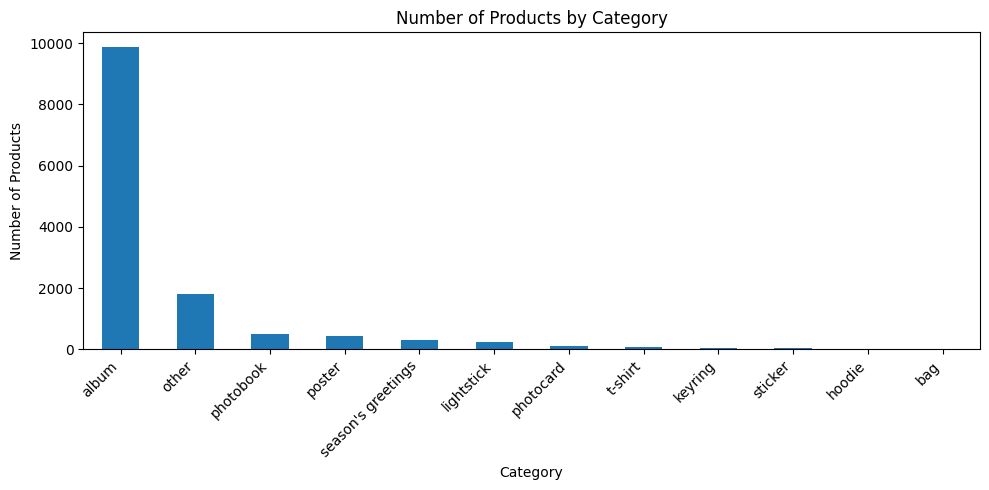

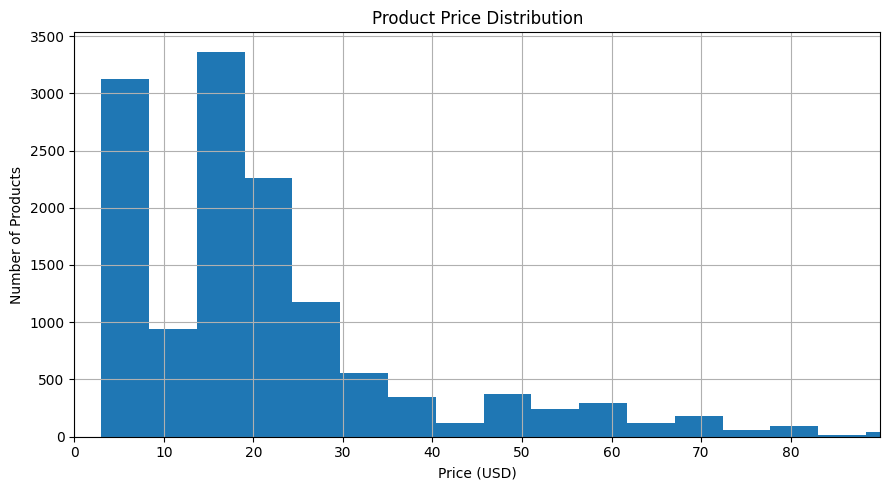

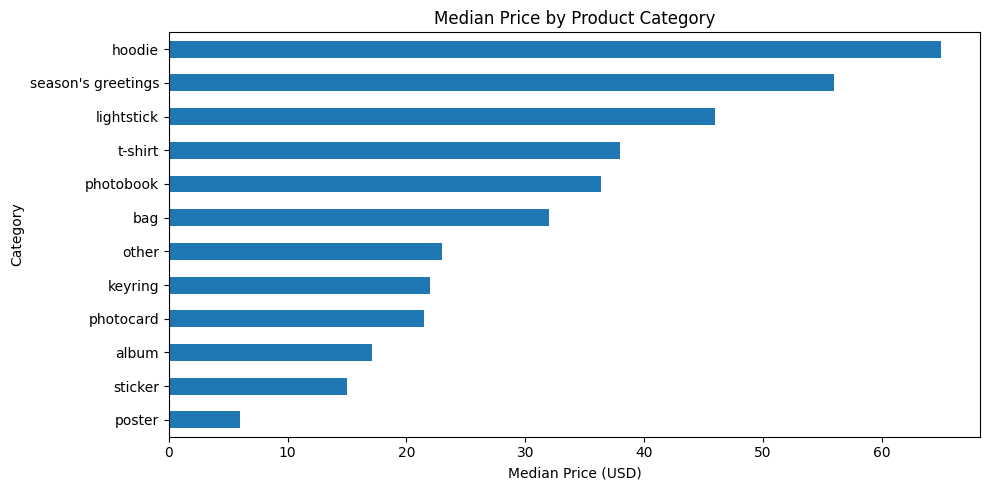

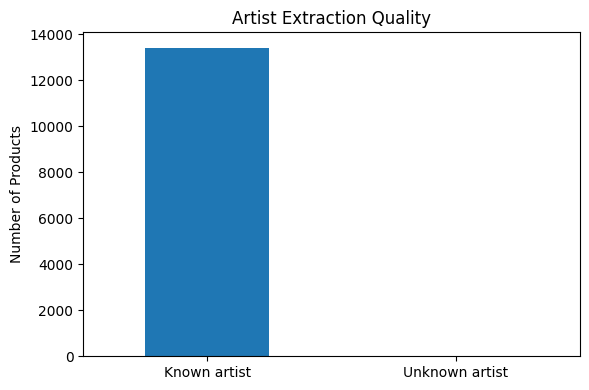


............SAMPLE PRODUCTS............


,name,artist,category,vendor,price_usd
9030,방탄소년단 | BTS | 5TH MINI ALBUM [ LOVE YOURSELF: ...,BTS,album,musicplaza,3.99
12970,DreamNote - 2nd single album [Dream:us],DREAMNOTE,album,kpopstoreinusa,16.99
3817,ENOi - [W.A.Y(雨) - WhereAreYou] Special Album,ENOI,album,kpopalbums,17.16
11010,Pre-Order - NCT 127 BAKER HOUSE Room Kit,NCT,other,smglobalshop,40.00
1493,SEVENTEEN - [Face the Sun] 4th Album KIHNO KIT...,SEVENTEEN,album,kpopalbums,21.78
9001,업텐션 | UP10TION | 2ND ALBUM [ CONNECTION ] | (I...,UP10TION,album,musicplaza,2.99
7796,"에스에프나인 | SF9 [ ME, ANOTHER ME ] INSEONG PHOTO ...",SF9,other,musicplaza,49.99
10480,정세운 | JEONG SEWOON | 2ND MINI ALBUM [ ANOTHER ...,JEONG SEWOON,album,musicplaza,2.99
11667,MONSTA X Official Goods - Slogan Ver.3,MONSTA X OFFICIAL GOODS,other,kpopstoreinusa,32.99
2900,Monsta X - [Take.2 We Are Here] 2nd Album Ver.II,MONSTA X,album,kpopalbums,17.16


In [84]:
# Check cleaned data with tables and graphs
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Dataset summary
print("............DATASET SUMMARY............")
print("Total products:", len(df))
print("Unique artists:", df["artist"].nunique())
print("Unique stores:", df["vendor"].nunique())
print("Product categories:", df["category"].nunique())
print("Median price (USD):", round(df["price_usd"].median(), 2))
print("Missing values:", df.isna().sum().sum())
print("Duplicate products:", df.duplicated(["name", "vendor"]).sum())

# 2. Check artist extraction
unknown = df["artist"].astype(str).str.lower().eq("unknown")
print("\n............ARTIST CHECK............")
print("Unknown artists:", unknown.sum())
print("Unknown percentage:", round(unknown.mean() * 100, 2), "%")

# 3. Show price statistics by category
print("\n............PRICE BY CATEGORY............")
display(
    df.groupby("category")["price_usd"]
      .agg(["count", "min", "median", "mean", "max"])
      .round(2)
      .sort_values("count", ascending=False)
)

# 4. Product categories
plt.figure(figsize=(10, 5))
df["category"].value_counts().plot(kind="bar")
plt.title("Number of Products by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 5. Price distribution
plt.figure(figsize=(9, 5))
df["price_usd"].hist(bins=50)
plt.title("Product Price Distribution")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Products")
plt.xlim(0, df["price_usd"].quantile(0.99))
plt.tight_layout()
plt.show()

# 6. Median price by category
plt.figure(figsize=(10, 5))
df.groupby("category")["price_usd"].median().sort_values().plot(kind="barh")
plt.title("Median Price by Product Category")
plt.xlabel("Median Price (USD)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# 7. Artist extraction quality
artist_status = pd.Series({
    "Known artist": (~unknown).sum(),
    "Unknown artist": unknown.sum()
})

plt.figure(figsize=(6, 4))
artist_status.plot(kind="bar")
plt.title("Artist Extraction Quality")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 8. Show sample products for manual checking
print("\n............SAMPLE PRODUCTS............")
display(
    df[["name", "artist", "category", "vendor", "price_usd"]]
    .sample(min(15, len(df)), random_state=42)
)

**In summary**

After cleaning the K-pop merchandise dataset, the results show:

- **Total products:** 13,438
- **Unique artists:** 2,187
- **Stores:** 6
- **Product categories:** 12
- **Median product price:** $18.00 USD
- **Missing values:** 0
- **Duplicate products:** 0

Also from my manually checks the cleaned dataset, while it shown cleaned artist with all component goods. However there is still unknown in artist column

Then after I have completed clean all unknown and show no **unknown** in last bargraph, however, there is still some of incorrect k-pop boy band.

For example, if you notice in no. **11667** artist name was incorrectly "MONSTA X OFFICIAL GOODS", which actual name is "MONSTA X" publiced in internet.


----

**Key Findings**

1. **Product Categories:** Albums are the largest category with 9,860 products. Other categories include photobooks, posters, lightsticks, and photocards.

2. **Price Distribution:** Most products are in the lower price range, while some merchandise has much higher prices.

3. **Median Prices:** Posters have a low median price of $5.99, while lightsticks ($45.99) and hoodies ($65.00) have higher median prices.



# 5. Price Labels, Product Features, and Graphs

in this stage will prepares product data for price classification using GAT and FAGCN.

**Price Labels** -> Products are grouped into three balanced price ranking : **Budget, Mid, and Premium**, based on USD prices.

**Product Features** The models use four key features:
1. **Product Name:** TF-IDF and SVD for text analysis.
2. **Category:** Product type, such as albums or lightsticks.
3. **Region:** Store location (KR, US, or other).
4. **Artist Catalogue:** Number of products linked to each artist.

**Graph Construction** Two graphs represent product relationships:
1. **Artist Graph:** Connects products from the same artist.
2. **Category Graph:** Connects products in the same category.


**Graph Quality**
**Edge homophily** measures how often connected products share the same price tier, helping assess graph relationships before comparing GAT and FAGCN.

In [85]:
!pip install -q torch_geometric

In [86]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# Price Classification into rank
RANK_NAMES = ["budget", "mid", "premium"]


# Divide into three balanced price 
def make_labels(prices, n_tiers=N_TIERS):
    # Rank prices first, then split into equal groups
    return pd.qcut(prices.rank(method="first"), n_tiers, labels=False).to_numpy()


# product info into nums
def make_products(frame, n_text_dims=64):
    tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=20000)
    # product names into TF-IDF 
    text = tfidf.fit_transform(frame["name"].fillna(""))
    # number of text dimensions
    k = max(2, min(n_text_dims, text.shape[1] - 1, len(frame) - 1))
    # Reduce TF-IDF dimensions using SVD
    blocks, names = [TruncatedSVD(n_components=k, random_state=SEED).fit_transform(text)], [f"name_svd_{i}" for i in range(k)]
    # Encode category and region as numerical features
    for col in ("category", "region"):
        # one-hot encoder
        dummies = pd.get_dummies(frame[col].astype(str), prefix=col)
        # encoded features and their names
        blocks.append(dummies.to_numpy(float)); names += list(dummies.columns)

    # log-transformed number of products' artists
    blocks.append(np.log1p(frame.groupby("artist")["name"].transform("count").to_numpy(float))[:, None])
    # Name'artist catalogue size feature
    names.append("artist_catalogue_size_log")
    # Combine all feature blocks
    x = np.hstack(blocks)
    # back to standard -> return in metrix
    return ((x - x.mean(0)) / (x.std(0) + 1e-8)).astype(np.float32), names


# Build graph connections -> products sharing the same group
def make_edges(frame, by, max_neighbours=MAX_NEIGHBOURS, seed=SEED):
    rng = np.random.default_rng(seed) # random number generator for reproducible sampling
    src, dst = [], [] # srouce and destination
        # Group products by artist or cat
    for idx in frame.groupby(by).indices.values():
        idx = np.asarray(idx)
        for i in idx:
            # other products in the same group
            others = idx[idx != i]
# skip products with neighbor
            if len(others) == 0:
                continue
            pick = others if len(others) <= max_neighbours else rng.choice(others, max_neighbours, replace=False)
            src += [i] * len(pick); dst += pick.tolist()
    if not src:
        return np.zeros((2, 0), dtype=np.int64)
    e = np.array([src, dst], dtype=np.int64)
    return np.unique(np.hstack([e, e[::-1]]), axis=1)


# Measure products share the same price rank
def edge_homophily(edge_index, y):
    # Compare the price labels 
    return float((y[edge_index[0]] == y[edge_index[1]]).mean()) if edge_index.size else float("nan")


# the price labels for each product
y = make_labels(df["price_usd"])
# product feature matrix
x, feature_names = make_products(df)
# artist and category graphs
graphs = {g: make_edges(df, g) for g in EDGE_TYPES}


# Calculate homophily for each graph
homophily = {g: round(edge_homophily(e, y), 4) for g, e in graphs.items()}

print("Features:", x.shape, "| Edges:", {g: e.shape[1] for g, e in graphs.items()})
print("Edge homophily ratio h:", homophily)

Features: (13438, 79) | Edges: {'artist': 174396, 'category': 267490}
Edge homophily ratio h: {'artist': 0.3794, 'category': 0.3849}


**UNIT CHECK on:** 

1. Homophily: Verifies the graph relationship calculation.
2. Features: Ensures product prices are excluded to prevent data leakage.
3. Price Tiers: Confirms balanced Budget, Mid, and Premium classes.
4. Graph Structure: Checks valid connections, no self-loops, and undirected edges.

All unit checks must pass before proceeding to GAT and FAGCN training.


In [87]:
test_small_sample_of_homo = np.array([[0, 1, 2], [1, 2, 3]])
assert edge_homophily(test_small_sample_of_homo, np.array([0, 0, 1, 1])) == 2 / 3, "Homophily formula is wrong"

# Check that price is not included in the input features
assert not any("price" in n.lower() for n in feature_names), "Price leaks into the features"

# Check feature dimensions , invalid values
assert x.shape == (len(df), len(feature_names)) and np.isfinite(x).all(), "Bad feature matrix"

# Check if the three price rank are balanced
counts = np.bincount(y, minlength=N_TIERS)
assert counts.min() >= 0.9 * counts.max(), f"Price ranks are unbalanced: {counts}"

# Graph connection checking
for g, e in graphs.items():
    assert e.size and e.min() >= 0 and e.max() < len(df), f"Invalid node ids in {g} graph"

    # whether nodes connect
    assert (e[0] != e[1]).all(), f"self-loops in {g} graph"

    edges = e.T
    reverse_edges = e[::-1].T

    assert np.array_equal(
        np.unique(edges, axis=0),
        np.unique(reverse_edges, axis=0)
    ), f"{g} graph is not undirected"

# Display the validation results
print("PASSED -> Price RANKs", dict(zip(RANK_NAMES, counts.tolist())), "| h =", homophily)

PASSED -> Price RANKs {'budget': 4479, 'mid': 4479, 'premium': 4480} | h = {'artist': 0.3794, 'category': 0.3849}


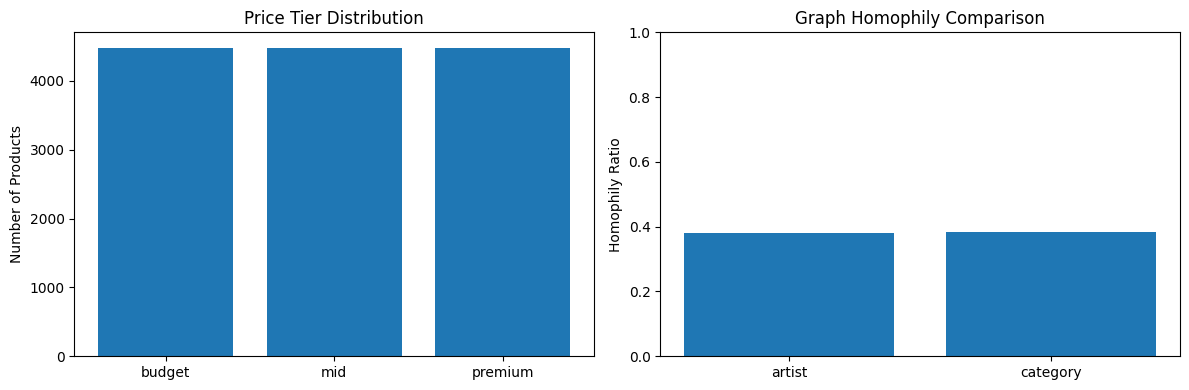

In [88]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Price tier distribution
axes[0].bar(RANK_NAMES, counts)
axes[0].set_title("Price Tier Distribution")
axes[0].set_ylabel("Number of Products")

# Edge homophily comparison
axes[1].bar(list(homophily.keys()), list(homophily.values()))
axes[1].set_title("Graph Homophily Comparison")
axes[1].set_ylabel("Homophily Ratio")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Validation Results**

In section of Price Ranking, All three groups are balanced, with approximately 4,480 products each. Then graph homophily already stated thta Artist (37.94%) and Category (38.49%) show relatively low price-tier similarity between connected products.

# 6. Models & Training

Which will train three models for K-pop merchandise price classification.


**Model Comparison** 

> Baseline model will come in all model and notebook which I will use to compare whether worthwhile to use complex model (System A & System B) or baseline model

1. MLP: Baseline model using product features without graph connections.
2. GAT: Uses attention to learn from connected products.
3. FAGCN: Learns from both similar and different product relationships.

**Training Step**
1. Data Split
2. Training
3. Evaluate by usinh Macro-F1 for three price ranking
4. Early stopping for select best validation from state in no.3
5. Reliability in 5 randome spilts comparisom


In [89]:
!pip install -q torch_geometric

In [90]:
import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import FAConv, GATConv
from sklearn.metrics import f1_score


# Calculate Macro-F1 across all price tiers
def macro_f1(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


# MLP baselin -> uses product features without graph connections
class MLP(nn.Module):
    def __init__(self, d_in, n_cls, p):
        super().__init__()
        self.l1, self.l2, self.drop = nn.Linear(d_in, p["hidden"]), nn.Linear(p["hidden"], n_cls), p["dropout"]

    def forward(self, x, edge_index):
        # activation and dropout
        h = F.relu(self.l1(F.dropout(x, self.drop, self.training)))
        return self.l2(F.dropout(h, self.drop, self.training))


# GAT -> uses attention to learn from connected products
class GAT(nn.Module):
    def __init__(self, d_in, n_cls, p):
        super().__init__()
        self.drop = p["dropout"]
        self.c1 = GATConv(d_in, p["hidden"], heads=p["heads"], dropout=self.drop)         # graph attention layer with multiple heads
        self.c2 = GATConv(p["hidden"] * p["heads"], n_cls, heads=1, concat=False, dropout=self.drop)         #  price ranking classification


    def forward(self, x, edge_index):
        # Learn product relationships using graph attention
        h = F.elu(self.c1(F.dropout(x, self.drop, self.training), edge_index))
        return self.c2(F.dropout(h, self.drop, self.training), edge_index)


# FAGCN -> learns from similar and different neighbouring products
class FAGCN(nn.Module):
    def __init__(self, d_in, n_cls, p):
        super().__init__()
        self.drop = p["dropout"]
        self.lin_in, self.lin_out = nn.Linear(d_in, p["hidden"]), nn.Linear(p["hidden"], n_cls)         # Input and output of transformation layers
        self.convs = nn.ModuleList(FAConv(p["hidden"], eps=p["eps"], dropout=self.drop) for _ in range(p["layers"]))         # Frequency-adaptive graph convolution layers

    def forward(self, x, edge_index):
        # initial node features
        h0 = h = F.relu(self.lin_in(F.dropout(x, self.drop, self.training)))
        h = F.dropout(h, self.drop, self.training)
        #frequency-adaptive graph convolutions
        for conv in self.convs:
            h = conv(h, h0, edge_index)
        return self.lin_out(F.dropout(h, self.drop, self.training))


# Register available model architectures
ARCH = {"mlp": MLP, "gat": GAT, "fagcn": FAGCN}


# Create stratified training, validation and test splits
def make_masks(labels, seed):
    idx = np.arange(len(labels))
    tr, rest = train_test_split(idx, train_size=SPLIT["train"], stratify=labels, random_state=seed) # split from ramaining data
    # Devide sample of val and test
    va, te = train_test_split(rest, train_size=SPLIT["val"] / (SPLIT["val"] + SPLIT["test"]), 
                              stratify=labels[rest], random_state=seed)
# convert spilt in boolean marks
    masks = [np.zeros(len(labels), dtype=bool) for _ in range(3)]
    for m, part in zip(masks, (tr, va, te)):
        m[part] = True
    return masks


def train_eval(params, edge_index, masks, seed):
    set_seed(seed)
    dev = get_device()

    X, Y, E = torch.tensor(x, device=dev), torch.tensor(y, device=dev), torch.tensor(edge_index, device=dev)     # Move features, labels and graph edges to the device
    tr, va, te = (torch.tensor(m, device=dev) for m in masks)

    model = ARCH[params["kind"]](x.shape[1], N_TIERS, params).to(dev)   # Initialize the selected model and Adam optimizer
    opt = torch.optim.Adam(model.parameters(), lr=TRAIN["lr"], weight_decay=TRAIN["weight_decay"])

    best, best_state, wait, t0 = -1.0, None, 0, time.perf_counter() # Track the best val outcomes
    # Full training
    for _ in range(TRAIN["epochs"]):
        model.train(); opt.zero_grad()
        F.cross_entropy(model(X, E)[tr], Y[tr]).backward(); opt.step() # training loss & update weights
        model.eval()
        # Generate predictions without updating gradients
        with torch.no_grad():
            pred = model(X, E).argmax(1).cpu().numpy()
        score = macro_f1(y[masks[1]], pred[masks[1]])

        # Save
        if score > best:
            best, wait, best_state = score, 0, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= TRAIN["patience"]:
                break

# RECORD
    seconds = time.perf_counter() - t0
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        return model(X, E).argmax(1).cpu().numpy(), seconds

**UNIT TEST CHECKING & EXPERIMENT**

To ensure if model completly by checking 2 things such as:
1. Verifies that every model, graph, and random seed has been evaluated.
2. Ensures all Macro-F1 scores are valid and within the 0–1 range.

In [91]:
rows = []

for gname, edges in graphs.items():
    for system, params in MODELS.items():
        for s in range(N_SEEDS):
            masks = make_masks(y, SEED + s)
            pred, secs = train_eval(params, edges, masks, SEED + s)

            te = masks[2]
            test = pd.DataFrame({
                "y_true": y[te],
                "y_pred": pred[te],
                "region": df.loc[te, "region"].to_numpy()
            })

            f1_by_region = {
                r: macro_f1(g["y_true"], g["y_pred"])
                for r, g in test.groupby("region")
                if len(g) >= 10
            }

            rows.append({
                "graph": gname,
                "system": system,
                "model": params["kind"],
                "seed": s,
                "macro_f1": macro_f1(y[te], pred[te]),
                "accuracy": float((y[te] == pred[te]).mean()),
                "region_f1_gap": (
                    max(f1_by_region.values()) - min(f1_by_region.values())
                    if len(f1_by_region) > 1 else 0.0
                ),
                "train_time_s": secs,
                # a listing priced two tiers above what similar items suggest -> candidate for a pricing review
                "overpriced_flag_rate": float(((y[te] - pred[te]) >= 2).mean()),
            })

        print(f"done: {gname:9s} {system}")

runs = pd.DataFrame(rows)

summary = runs.drop(columns="seed").groupby(
    ["graph", "system", "model"]
).agg(["mean", "std"])

summary.columns = ["_".join(c) for c in summary.columns]
summary = summary.reset_index()

runs.to_csv(TABLES / f"{TASK}__all_runs.csv", index=False)
summary.to_csv(TABLES / f"{TASK}__summary_by_graph.csv", index=False)

display(
    summary[
        [
            "graph",
            "system",
            "model",
            "macro_f1_mean",
            "macro_f1_std",
            "region_f1_gap_mean",
            "train_time_s_mean"
        ]
    ].round(3)
)

done: artist    A
done: artist    B
done: artist    baseline_mlp
done: category  A
done: category  B
done: category  baseline_mlp


,graph,system,model,macro_f1_mean,macro_f1_std,region_f1_gap_mean,train_time_s_mean
0,artist,A,gat,0.493,0.007,0.102,4.023
1,artist,B,fagcn,0.775,0.010,0.302,3.119
2,artist,baseline_mlp,mlp,0.775,0.011,0.306,1.065
3,category,A,gat,0.602,0.015,0.218,7.070
4,category,B,fagcn,0.776,0.013,0.300,3.978
5,category,baseline_mlp,mlp,0.775,0.011,0.306,1.061


In [92]:
# Check the expected number of experiments
expected = len(EDGE_TYPES) * len(MODELS) * N_SEEDS
assert "runs" in globals(), "Run the Experiment Cell (rows = []) first"
assert len(runs) == expected, f"{len(runs)} runs, expected {expected}"

assert not runs.duplicated(subset=["graph", "system", "seed"]).any(), "duplicate experiments"
assert set(runs["graph"]) == set(EDGE_TYPES), "missing graph experiments"
assert set(runs["system"]) == set(MODELS), "missing model experiments"
assert set(runs["seed"]) == set(range(N_SEEDS)), "missing random seeds"

# Validate Macro-F1 scores
assert runs["macro_f1"].between(0, 1).all() and runs["macro_f1"].notna().all(), "invalid F1 values"

# Confirm successful validation
print("PASS as expected:", expected, "runs")

PASS as expected: 30 runs


# 7. Performance Comparison of three model 

Which will from those three:
- Macro-F1 : Performance prediction of three price ranking
- Errors bars : Performance varaition acorss random 5 seeds
- Graph comparison : Show how diffrent product relationships affect model performance

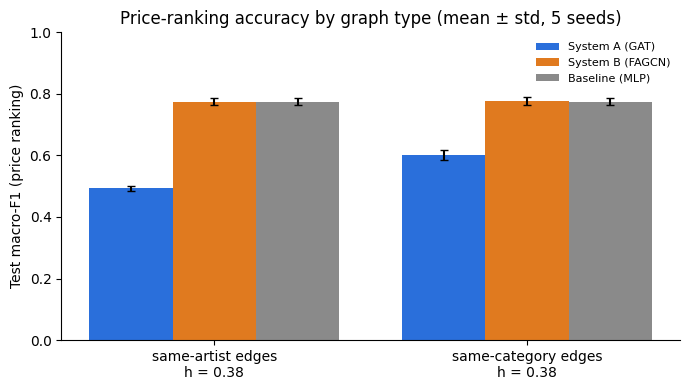

In [93]:
import matplotlib.pyplot as plt

# Define colors for each model
COLORS = {"A": "#2a6fdb", "B": "#e07a1f", "baseline_mlp": "#8a8a8a"}

fig, ax = plt.subplots(figsize=(7, 4))
systems, width = list(MODELS), 0.8 / len(MODELS)

# Macro-F1 results for each system
for i, s in enumerate(systems):
    sub = summary[summary["system"] == s].set_index("graph").reindex(EDGE_TYPES)
    xs = [g + (i - (len(systems) - 1) / 2) * width for g in range(len(EDGE_TYPES))]
    ax.bar(xs, sub["macro_f1_mean"], width, yerr=sub["macro_f1_std"], capsize=3, color=COLORS[s],
           label=f"{'System ' + s if s in ['A', 'B'] else 'Baseline'} ({MODELS[s]['kind'].upper()})")

# graph types and homophily values
ax.set_xticks(range(len(EDGE_TYPES)), [f"same-{g} edges\nh = {homophily[g]:.2f}" for g in EDGE_TYPES])

ax.set_ylabel("Test macro-F1 (price ranking)"); ax.set_ylim(0, 1)
ax.set_title("Price-ranking accuracy by graph type (mean ± std, 5 seeds)")

#Save
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIGURES / f"{TASK}_gnn_by_graph.png", dpi=200); plt.show()

# 8. SAVE ALL Figures

In [94]:
primary = runs[runs["graph"] == PRIMARY_GRAPH]

mlp_f1 = primary.loc[primary["system"] == "baseline_mlp", "macro_f1"].mean()

# Save evaluation results for each system
for system, params in MODELS.items():
    sub = primary[primary["system"] == system]
    save_result(
        TASK, system, params["kind"].upper(),
        # Technical performance
        technical={"macro_f1": sub["macro_f1"].mean(), "macro_f1_std": sub["macro_f1"].std(),
                   "accuracy": sub["accuracy"].mean(), "mlp_macro_f1": mlp_f1,
                   "edge_homophily": homophily[PRIMARY_GRAPH], "graph": PRIMARY_GRAPH},
        # Business performance 
        business={"train_time_s": sub["train_time_s"].mean(), "overpriced_flag_rate": sub["overpriced_flag_rate"].mean()},
        # Regional performance 
        governance={"region_f1_gap": sub["region_f1_gap"].mean()},
        notes=f"{N_SEEDS} seeds, {len(df)} products, decision graph = same-{PRIMARY_GRAPH} edges",
        extra={"homophily": homophily, "summary_by_graph": summary.to_dict(orient="records")},
    )

saved /content/Results/metrics/3_Global_Pricing__A.json
saved /content/Results/metrics/3_Global_Pricing__B.json
saved /content/Results/metrics/3_Global_Pricing__baseline_mlp.json


# 9. Conclusion

.......................................................
FINAL GLOBAL PRICING RESULTS
.......................................................

1. DATASET OVERVIEW
Total products: 13,438
Unique artists: 2,187
Stores: 6
Categories: 12
Median price: $18.00 USD

2. PRICE TIER DISTRIBUTION


,Products
budget,4479
mid,4479
premium,4480



2.1 PRICE RANGES (USD)


,Price Tier,Products,Price Range (USD),Median Price (USD)
0,budget,4479,$2.99 - $14.79,5.99
1,mid,4479,$14.79 - $22.21,18.00
2,premium,4480,$22.21 - $269.99,32.00


BUDGET  : $2.99 - $14.79 | 4,479 products
MID     : $14.79 - $22.21 | 4,479 products
PREMIUM : $22.21 - $269.99 | 4,480 products


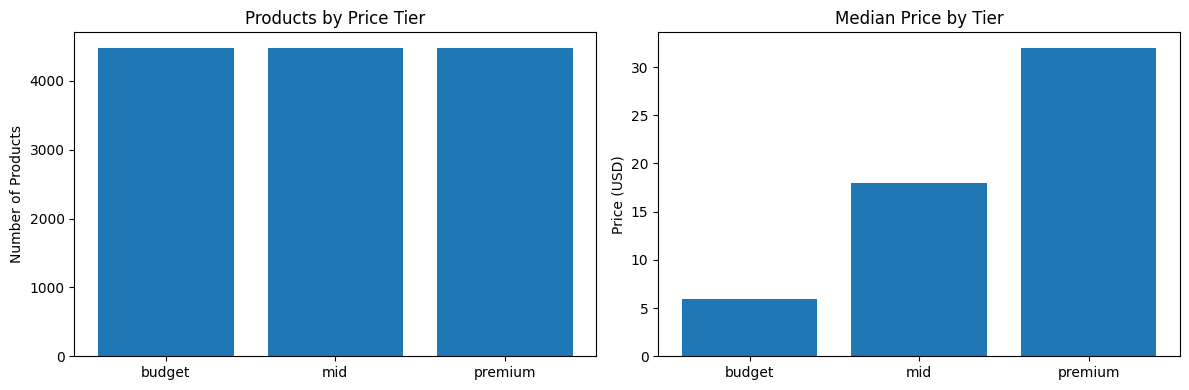


3. GRAPH QUALITY


,Graph,Nodes,Directed edge entries,Homophily
0,artist,13438,174396,0.3794
1,category,13438,267490,0.3849



4. MODEL PERFORMANCE


,rank,graph,system,model,macro_f1_mean,macro_f1_std,accuracy_mean,region_f1_gap_mean,train_time_s_mean,overpriced_flag_rate_mean
0,1,artist,B,fagcn,0.7752,0.0100,0.7699,0.3017,3.1190,0.0028
1,2,artist,baseline_mlp,mlp,0.7745,0.0114,0.7694,0.3065,1.0651,0.0030
2,3,artist,A,gat,0.4928,0.0074,0.4932,0.1019,4.0225,0.0618
3,1,category,B,fagcn,0.7762,0.0126,0.7711,0.3002,3.9777,0.0033
4,2,category,baseline_mlp,mlp,0.7745,0.0114,0.7694,0.3065,1.0614,0.0030
5,3,category,A,gat,0.6016,0.0154,0.6008,0.2183,7.0696,0.0439



5. PRIMARY GRAPH: ARTIST


,rank,graph,system,model,macro_f1_mean,macro_f1_std,accuracy_mean,region_f1_gap_mean,train_time_s_mean,overpriced_flag_rate_mean
0,1,artist,B,fagcn,0.7752,0.0100,0.7699,0.3017,3.1190,0.0028
1,2,artist,baseline_mlp,mlp,0.7745,0.0114,0.7694,0.3065,1.0651,0.0030
2,3,artist,A,gat,0.4928,0.0074,0.4932,0.1019,4.0225,0.0618



6. BEST MODEL
System: B
Model: FAGCN
Graph: artist
Macro-F1: 0.7752
Accuracy: 0.7699
Training time: 3.12 seconds
Regional F1 gap: 0.3017


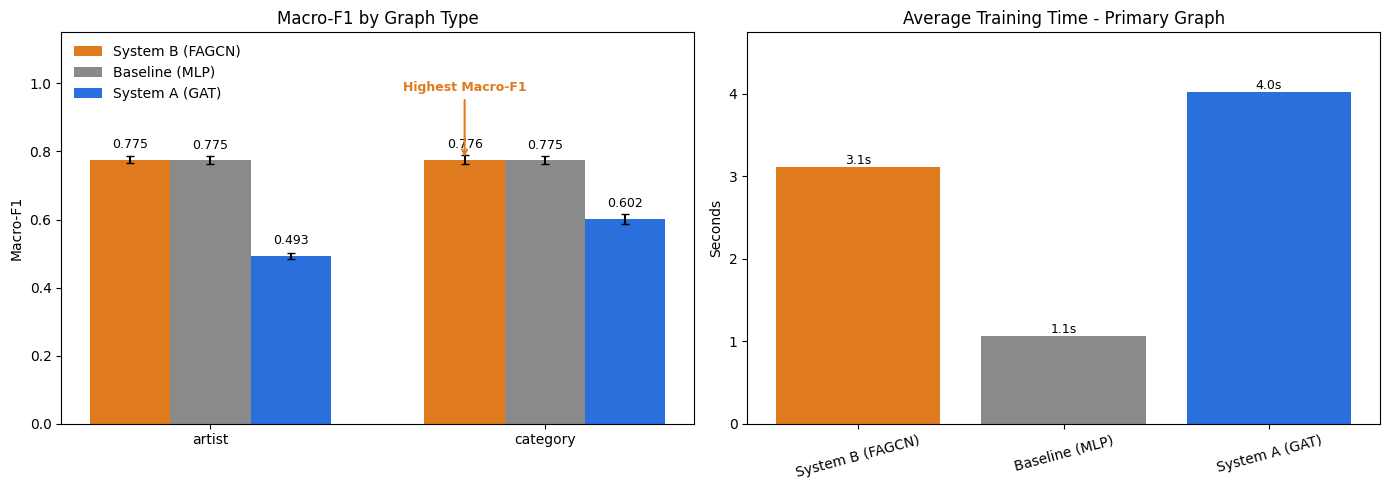


7. BUSINESS CONCLUSION
B (FAGCN) achieved the highest average Macro-F1 (0.7752) on the artist graph.

PRICE SEGMENT SUMMARY
Budget: $2.99 - $14.79
Mid: $14.79 - $22.21
Premium: $22.21 - $269.99

Final summary saved: /content/Results/tables/3_Global_Pricing__final_summary.csv
Price ranges saved: /content/Results/tables/3_Global_Pricing__price_ranges.csv


In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

#  Dataset summary
print("." * 55)
print("FINAL GLOBAL PRICING RESULTS")
print("." * 55)

print("\n1. DATASET OVERVIEW")
print(f"Total products: {len(df):,}")
print(f"Unique artists: {df['artist'].nunique():,}")
print(f"Stores: {df['vendor'].nunique():,}")
print(f"Categories: {df['category'].nunique():,}")
print(f"Median price: ${df['price_usd'].median():.2f} USD")

# Price tier distribution
print("\n2. PRICE TIER DISTRIBUTION")
tier_counts = pd.Series(y).value_counts().reindex(
    range(N_TIERS), fill_value=0
)
tier_counts.index = RANK_NAMES
display(tier_counts.rename("Products").to_frame())

# Price ranges from lowest to highest
print("\n2.1 PRICE RANGES (USD)")

price_tiers = pd.DataFrame({
    "Price Tier": [RANK_NAMES[int(i)] for i in y],
    "Price USD": df["price_usd"].to_numpy()
})

price_ranges = (
    price_tiers.groupby("Price Tier")["Price USD"]
    .agg(Products="count", Min_USD="min", Median_USD="median", Max_USD="max")
    .reindex(RANK_NAMES)
    .reset_index()
)

price_ranges["Price Range (USD)"] = price_ranges.apply(
    lambda r: f"${r['Min_USD']:,.2f} - ${r['Max_USD']:,.2f}",
    axis=1
)

display(
    price_ranges[
        ["Price Tier", "Products", "Price Range (USD)", "Median_USD"]
    ].rename(columns={"Median_USD": "Median Price (USD)"})
    .round(2)
)

for _, row in price_ranges.iterrows():
    print(
        f"{row['Price Tier'].upper():8s}: "
        f"${row['Min_USD']:,.2f} - ${row['Max_USD']:,.2f} "
        f"| {int(row['Products']):,} products"
    )

# Price range visualization
fig, axes_price = plt.subplots(1, 2, figsize=(12, 4))

axes_price[0].bar(
    price_ranges["Price Tier"],
    price_ranges["Products"]
)
axes_price[0].set_title("Products by Price Tier")
axes_price[0].set_ylabel("Number of Products")

axes_price[1].bar(
    price_ranges["Price Tier"],
    price_ranges["Median_USD"]
)
axes_price[1].set_title("Median Price by Tier")
axes_price[1].set_ylabel("Price (USD)")

plt.tight_layout()
plt.show()

# Graph quality
print("\n3. GRAPH QUALITY")
graph_table = pd.DataFrame([
    {
        "Graph": g,
        "Nodes": len(df),
        "Directed edge entries": e.shape[1],
        "Homophily": homophily[g]
    }
    for g, e in graphs.items()
])
display(graph_table)

# Model performance
print("\n4. MODEL PERFORMANCE")

model_results = (
    summary[
        [
            "graph", "system", "model",
            "macro_f1_mean", "macro_f1_std",
            "accuracy_mean",
            "region_f1_gap_mean",
            "train_time_s_mean",
            "overpriced_flag_rate_mean"
        ]
    ]
    .copy()
)

model_results["graph"] = pd.Categorical(
    model_results["graph"],
    categories=list(EDGE_TYPES),
    ordered=True
)

model_results = (
    model_results
    .sort_values(
        ["graph", "macro_f1_mean", "system"],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

model_results.insert(
    0,
    "rank",
    model_results.groupby("graph", observed=True).cumcount() + 1
)

display(model_results.round(4))

# Primary graph comparison
print(f"\n5. PRIMARY GRAPH: {PRIMARY_GRAPH.upper()}")

primary_results = (
    model_results[model_results["graph"] == PRIMARY_GRAPH]
    .sort_values(
        ["macro_f1_mean", "system"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(primary_results.round(4))

# Best-performing model
best = primary_results.iloc[0]

print("\n6. BEST MODEL")
print(f"System: {best['system']}")
print(f"Model: {best['model'].upper()}")
print(f"Graph: {best['graph']}")
print(f"Macro-F1: {best['macro_f1_mean']:.4f}")
print(f"Accuracy: {best['accuracy_mean']:.4f}")
print(f"Training time: {best['train_time_s_mean']:.2f} seconds")
print(f"Regional F1 gap: {best['region_f1_gap_mean']:.4f}")

# Performance comparison chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

graph_names = list(EDGE_TYPES)
x_pos = np.arange(len(graph_names))

colors = {
    "A": "#2a6fdb",
    "B": "#e07a1f",
    "baseline_mlp": "#8a8a8a"
}

labels = {
    "A": "System A (GAT)",
    "B": "System B (FAGCN)",
    "baseline_mlp": "Baseline (MLP)"
}

systems_order = (
    primary_results
    .sort_values(
        ["macro_f1_mean", "system"],
        ascending=[False, True]
    )["system"]
    .tolist()
)

width = 0.24

for i, system in enumerate(systems_order):
    sub = (
        model_results[model_results["system"] == system]
        .set_index("graph")
        .reindex(graph_names)
    )

    positions = x_pos + (i - (len(systems_order) - 1) / 2) * width

    bars = axes[0].bar(
        positions,
        sub["macro_f1_mean"],
        width=width,
        yerr=sub["macro_f1_std"],
        capsize=3,
        color=colors[system],
        label=labels[system]
    )

    for bar, score in zip(bars, sub["macro_f1_mean"]):
        if pd.notna(score):
            axes[0].text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.025,
                f"{score:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

axes[0].set_xticks(x_pos, graph_names)
axes[0].set_title("Macro-F1 by Graph Type")
axes[0].set_ylabel("Macro-F1")
axes[0].set_ylim(0, 1.15)
axes[0].legend(frameon=False)

best_graph_row = model_results.loc[
    model_results["macro_f1_mean"].idxmax()
]

best_system = best_graph_row["system"]
best_graph = best_graph_row["graph"]
best_score = best_graph_row["macro_f1_mean"]

best_i = systems_order.index(best_system)

best_x = (
    graph_names.index(best_graph)
    + (best_i - (len(systems_order) - 1) / 2) * width
)

axes[0].annotate(
    "Highest Macro-F1",
    xy=(best_x, best_score),
    xytext=(best_x, min(best_score + 0.20, 1.10)),
    ha="center",
    fontsize=9,
    fontweight="bold",
    color=colors[best_system],
    arrowprops=dict(
        arrowstyle="->",
        color=colors[best_system],
        lw=1.5
    )
)

time_results = (
    primary_results
    .set_index("system")
    .loc[systems_order]
)

time_bars = axes[1].bar(
    [labels[s] for s in systems_order],
    time_results["train_time_s_mean"],
    color=[colors[s] for s in systems_order]
)

for bar in time_bars:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}s",
        ha="center",
        va="bottom",
        fontsize=9
    )

axes[1].set_title("Average Training Time - Primary Graph")
axes[1].set_ylabel("Seconds")
axes[1].set_ylim(
    0,
    max(time_results["train_time_s_mean"].max() * 1.18, 1)
)
axes[1].tick_params(axis="x", labelrotation=15)

plt.tight_layout()
plt.show()

#  Business conclusion
print("\n7. BUSINESS CONCLUSION")
print(
    f"{best['system']} ({best['model'].upper()}) achieved the highest "
    f"average Macro-F1 ({best['macro_f1_mean']:.4f}) "
    f"on the {PRIMARY_GRAPH} graph."
)

print("\nPRICE SEGMENT SUMMARY")
for _, row in price_ranges.iterrows():
    print(
        f"{row['Price Tier'].capitalize()}: "
        f"${row['Min_USD']:,.2f} - ${row['Max_USD']:,.2f}"
    )

# 9. Save final summary
TABLES.mkdir(parents=True, exist_ok=True)

output_path = TABLES / f"{TASK}__final_summary.csv"
model_results.to_csv(output_path, index=False)

price_output_path = TABLES / f"{TASK}__price_ranges.csv"
price_output_path = TABLES / f"{TASK}__price_ranges.csv"
price_ranges.to_csv(price_output_path, index=False)

print(f"\nFinal summary saved: {output_path}")
print(f"Price ranges saved: {price_output_path}")

# 10. Extract from Google Drive

In [108]:
from google.colab import drive
from pathlib import Path
import shutil
import zipfile

# Connect Google Drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [109]:
# Create Google Drive folder
DRIVE_OUTPUT = Path("/content/drive/MyDrive/Kpop_MerchAI/Global_Pricing")
DRIVE_OUTPUT.mkdir(parents=True, exist_ok=True)

# Create ZIP file
ZIP_PATH = DRIVE_OUTPUT / "Global_Pricing_Results.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:

    # Add all result tables
    for file in TABLES.glob(f"{TASK}*.csv"):
        zipf.write(file, arcname=f"tables/{file.name}")

    # Add all figures
    for file in FIGURES.glob(f"{TASK}*.png"):
        zipf.write(file, arcname=f"figures/{file.name}")
        
    for file in METRICS.glob(f"{TASK}*.json"):
        zipf.write(file, arcname=f"metrics/{file.name}")

print("ZIP saved successfully!")
print("Location:", ZIP_PATH)
print("Size:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")

ZIP saved successfully!
Location: /content/drive/MyDrive/Kpop_MerchAI/Global_Pricing/Global_Pricing_Results.zip
Size: 0.06 MB


# 11. Live DEMO section

.......................................................
K-POP MERCH AI - Global Priceing in UNIT of LIVE DEMO VIDEO
.......................................................

1. INPUT DATA


,name,artist,category,price_usd
0,TWICE 11th MINI ALBUM BETWEEN 1&2,TWICE,album,22.9
1,1st Mini Album IM NAYEON,NAYEON,album,22.0
2,TWICE 1st Mini Album The Story Begins,TWICE,album,14.7
3,TWICE 3rd Mini Album TWICEcoaster : LANE 1,TWICE,album,15.6
4,Special Album TWICEcoaster : LANE 2,TWICE,album,17.4
5,4th Mini Album Signal,TWICE,album,17.4
6,TWICE 1st Repackage Album Merry & Happy,TWICE,album,18.3
7,TWICE 5th Mini Album What is Love?,TWICE,album,18.3
8,2nd Summer Special Album Summer Nights,TWICE,album,18.3
9,"TWICE 3rd Special Album The year of ""YES""",TWICE,album,19.3



2. PRICE RANKING: BUDGET TO PREMIUM


,name,artist,price_usd,price_tier
4638,갓세븐 | GOT7 | 2ND ALBUM [ FLIGHT LOG: TURBULENC...,GOT7,2.99,budget
4639,갓세븐 | GOT7 | 3RD ALBUM [ PRESENT: YOU ] | POST...,GOT7,2.99,budget
4761,김준수 | XIA | ALBUMS | POSTER ONLY,XIA,2.99,budget
2407,Block B Zico - [Television] 2nd Solo Mini Album,BLOCK B ZICO,14.79,mid
2422,THE BOYZ - [BE AWARE] 7th Mini Meta PLATFORM A...,THE BOYZ,14.79,mid
2527,Pentagon - [Demo_02] 5th Mini Album,PENTAGON,14.79,mid
572,(PRE-ORDER) Red Velvet - [The ReVe Festival 20...,RED VELVET,22.21,premium
871,SEULGI - [28 Reasons] 1st Mini Album SPECIAL V...,SEULGI,22.21,premium
1096,LOONA - [Flip That] Summer Special Mini Album ...,LOONA,22.21,premium



3. GRAPH STRUCTURE
ARTIST GRAPH | Nodes: 13,438 | Edge entries: 174,396 | Homophily: 0.3794
CATEGORY GRAPH | Nodes: 13,438 | Edge entries: 267,490 | Homophily: 0.3849

4. SYSTEM A VS SYSTEM B VS BASELINE


,rank,system,model,macro_f1_mean,macro_f1_std,accuracy_mean,train_time_s_mean,region_f1_gap_mean
0,1,B,fagcn,0.7752,0.0100,0.7699,3.1190,0.3017
1,2,baseline_mlp,mlp,0.7745,0.0114,0.7694,1.0651,0.3065
2,3,A,gat,0.4928,0.0074,0.4932,4.0225,0.1019



5. BEST PERFORMING MODEL
System: B
Model: FAGCN
Macro-F1: 0.7752
Accuracy: 0.7699

6. BUSINESS OUTPUT: PRICE RANGES


,Price Tier,Products,Min_USD,Median_USD,Max_USD,Price Range (USD)
0,budget,4479,2.99,5.99,14.79,$2.99 - $14.79
1,mid,4479,14.79,18.00,22.21,$14.79 - $22.21
2,premium,4480,22.21,32.00,269.99,$22.21 - $269.99



7. VISUAL COMPARISON


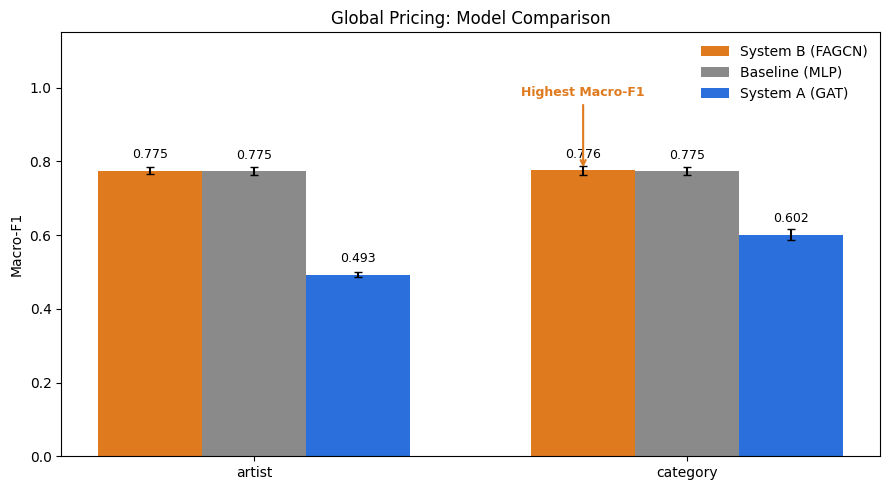


 COMPLETED


In [113]:
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("." * 55)
print("K-POP MERCH AI - Global Priceing in UNIT of LIVE DEMO VIDEO")
print("." * 55)

# Show dataset overview
print("\n1. INPUT DATA")
display(
    df[["name", "artist", "category", "price_usd"]]
    .head(10)
)

# Show price ranking
print("\n2. PRICE RANKING: BUDGET TO PREMIUM")

demo_prices = df[["name", "artist", "price_usd"]].copy()
demo_prices["price_tier"] = [
    RANK_NAMES[int(label)] for label in y
]

display(
    demo_prices
    .assign(
        price_tier=pd.Categorical(
            demo_prices["price_tier"],
            categories=list(RANK_NAMES),
            ordered=True
        )
    )
    .sort_values(["price_tier", "price_usd"])
    .groupby("price_tier", observed=True)
    .head(3)
)

# Show graph structure
print("\n3. GRAPH STRUCTURE")

for graph_name, edges in graphs.items():
    print(
        f"{graph_name.upper()} GRAPH | "
        f"Nodes: {len(df):,} | "
        f"Edge entries: {edges.shape[1]:,} | "
        f"Homophily: {homophily[graph_name]:.4f}"
    )

# Show model comparison
print("\n4. SYSTEM A VS SYSTEM B VS BASELINE")

demo_results = (
    summary[summary["graph"] == PRIMARY_GRAPH]
    .sort_values(
        ["macro_f1_mean", "system"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

demo_results.insert(
    0,
    "rank",
    range(1, len(demo_results) + 1)
)

display(
    demo_results[
        [
            "rank", "system", "model",
            "macro_f1_mean", "macro_f1_std",
            "accuracy_mean",
            "train_time_s_mean",
            "region_f1_gap_mean"
        ]
    ].round(4)
)

# Show best model
print("\n5. BEST PERFORMING MODEL")

best_demo = demo_results.iloc[0]

print(f"System: {best_demo['system']}")
print(f"Model: {best_demo['model'].upper()}")
print(f"Macro-F1: {best_demo['macro_f1_mean']:.4f}")
print(f"Accuracy: {best_demo['accuracy_mean']:.4f}")

# Show price ranges
print("\n6. BUSINESS OUTPUT: PRICE RANGES")

display(
    price_ranges
    .sort_values("Min_USD")
)

# Show performance chart
print("\n7. VISUAL COMPARISON")

colors = {
    "A": "#2a6fdb",
    "B": "#e07a1f",
    "baseline_mlp": "#8a8a8a"
}

labels = {
    "A": "System A (GAT)",
    "B": "System B (FAGCN)",
    "baseline_mlp": "Baseline (MLP)"
}

graph_names = list(EDGE_TYPES)
systems_order = demo_results["system"].tolist()
x_pos = np.arange(len(graph_names))
width = 0.24

fig, ax = plt.subplots(figsize=(9, 5))

for i, system in enumerate(systems_order):
    sub = (
        summary[summary["system"] == system]
        .set_index("graph")
        .reindex(graph_names)
    )

    positions = x_pos + (i - (len(systems_order) - 1) / 2) * width

    bars = ax.bar(
        positions,
        sub["macro_f1_mean"],
        width=width,
        yerr=sub["macro_f1_std"],
        capsize=3,
        color=colors[system],
        label=labels[system]
    )

    for bar, score in zip(bars, sub["macro_f1_mean"]):
        if pd.notna(score):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.025,
                f"{score:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

best_graph_row = summary.loc[summary["macro_f1_mean"].idxmax()]
best_system = best_graph_row["system"]
best_graph = best_graph_row["graph"]
best_score = best_graph_row["macro_f1_mean"]

best_i = systems_order.index(best_system)
best_x = (
    graph_names.index(best_graph)
    + (best_i - (len(systems_order) - 1) / 2) * width
)

ax.annotate(
    "Highest Macro-F1",
    xy=(best_x, best_score),
    xytext=(best_x, min(best_score + 0.20, 1.10)),
    ha="center",
    fontsize=9,
    fontweight="bold",
    color=colors[best_system],
    arrowprops=dict(
        arrowstyle="->",
        color=colors[best_system],
        lw=1.5
    )
)

ax.set_xticks(x_pos, graph_names)
ax.set_title("Global Pricing: Model Comparison")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.15)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

print("\n COMPLETED")